In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans 
from sklearn import metrics
from sklearn.metrics import mean_squared_error, confusion_matrix as calculate_confusion_matrix
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D

In [2]:
df = pd.read_csv('data/players_data-2024_2025.csv')

df.head()

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,Att (GK),Thr,Launch%,AvgLen,Opp,Stp,Stp%,#OPA,#OPA/90,AvgDist
0,1,Max Aarons,eng ENG,DF,Bournemouth,eng Premier League,24.0,2000.0,3,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Max Aarons,eng ENG,"DF,MF",Valencia,es La Liga,24.0,2000.0,4,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Rodrigo Abajas,es ESP,DF,Valencia,es La Liga,21.0,2003.0,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,James Abankwah,ie IRL,"DF,MF",Udinese,it Serie A,20.0,2004.0,6,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Keyliane Abdallah,fr FRA,FW,Marseille,fr Ligue 1,18.0,2006.0,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 2854 entries, 0 to 2853
Data columns (total 267 columns):
 #    Column                      Non-Null Count  Dtype  
---   ------                      --------------  -----  
 0    Rk                          2854 non-null   int64  
 1    Player                      2854 non-null   str    
 2    Nation                      2847 non-null   str    
 3    Pos                         2854 non-null   str    
 4    Squad                       2854 non-null   str    
 5    Comp                        2854 non-null   str    
 6    Age                         2846 non-null   float64
 7    Born                        2846 non-null   float64
 8    MP                          2854 non-null   int64  
 9    Starts                      2854 non-null   int64  
 10   Min                         2854 non-null   int64  
 11   90s                         2854 non-null   float64
 12   Gls                         2854 non-null   int64  
 13   Ast                        

In [4]:
df['Pos'].value_counts()

Pos
DF       859
MF       589
FW       371
FW,MF    325
MF,FW    230
GK       212
DF,MF    110
MF,DF     81
DF,FW     53
FW,DF     24
Name: count, dtype: int64

In [5]:
df = df[(df['Min'] >= 900) & (df['Pos'] != 'GK')]
df.info()

<class 'pandas.DataFrame'>
Index: 1450 entries, 5 to 2852
Columns: 267 entries, Rk to AvgDist
dtypes: float64(111), int64(121), str(35)
memory usage: 3.0 MB


In [6]:
info_columns = ['Player', 'Pos', 'Squad','Comp', 'Min']

features = [
    'G-PK', 'npxG', 'Sh', 'SoT', 'PrgR',
    'Ast', 'xAG', 'KP', 'SCA', 'PPA',
    'PrgP', 'Cmp%', '1/3', 'CrsPA', 'Touches',
    'PrgC', 'Carries', 'Succ', 'Dis', 'Recov',
    'Tkl', 'Int', 'Blocks_stats_defense', 'Clr', 'Att 3rd',
    'Def 3rd_stats_possession', 'Mid 3rd_stats_possession',
    'Att 3rd_stats_possession', 'Att Pen', 'Won',
]

df_new = df[info_columns + features].copy()

print(len(df_new), df_new[features].isna().sum().sum())

1450 0


In [7]:
df_new.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
Index: 1450 entries, 5 to 2852
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Player                    1450 non-null   str    
 1   Pos                       1450 non-null   str    
 2   Squad                     1450 non-null   str    
 3   Comp                      1450 non-null   str    
 4   Min                       1450 non-null   int64  
 5   G-PK                      1450 non-null   int64  
 6   npxG                      1450 non-null   float64
 7   Sh                        1450 non-null   int64  
 8   SoT                       1450 non-null   int64  
 9   PrgR                      1450 non-null   int64  
 10  Ast                       1450 non-null   int64  
 11  xAG                       1450 non-null   float64
 12  KP                        1450 non-null   int64  
 13  SCA                       1450 non-null   int64  
 14  PPA                     

In [8]:
numerical_features =  [f for f in features if f != 'Cmp%']

per_90 = df_new[numerical_features].div(df_new['Min'] / 90, axis=0)
df_p90 = pd.concat([df_new[info_columns], per_90, df_new[['Cmp%']]], axis=1)

In [9]:
df_p90.head()

,Player,Pos,Squad,Comp,Min,G-PK,npxG,Sh,SoT,PrgR,...,Int,Blocks_stats_defense,Clr,Att 3rd,Def 3rd_stats_possession,Mid 3rd_stats_possession,Att 3rd_stats_possession,Att Pen,Won,Cmp%
5,Yunis Abdelhamid,DF,Saint-Étienne,fr Ligue 1,1033,0.000000,0.017425,0.174250,0.087125,0.261375,...,1.219748,2.265247,4.966118,0.000000,36.069700,18.731849,1.219748,0.609874,1.655373,86.7
6,Himad Abdelli,"MF,FW",Angers,fr Ligue 1,2842,0.095004,0.101337,1.108374,0.253343,3.515130,...,0.823364,0.760028,0.886700,0.475018,9.278677,36.386348,18.905700,1.551724,0.411682,82.1
8,Ali Abdi,"DF,MF",Nice,fr Ligue 1,1393,0.323044,0.277818,1.873654,0.710696,6.525485,...,1.292175,1.292175,2.390524,0.710696,14.860014,22.548457,20.351759,3.230438,1.421393,74.0
10,Abel,DF,Osasuna,es La Liga,2074,0.086789,0.021697,0.520733,0.173578,3.992285,...,0.781099,1.258438,2.777242,0.347155,16.055931,26.253616,15.491803,0.824494,0.867888,72.5
13,Matthis Abline,FW,Nantes,fr Ligue 1,2768,0.260116,0.250361,2.373555,0.845376,5.494942,...,0.130058,0.487717,1.170520,0.162572,2.438584,12.420520,14.241329,4.617052,2.080925,65.2


In [10]:
from sklearn.preprocessing import StandardScaler
X = StandardScaler().fit_transform(df_p90[numerical_features + ['Cmp%']])

In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.90, random_state=0)
X_pca = pca.fit_transform(X)

print(f"Dimensions reduced from {X.shape[1]} to {X_pca.shape[1]}")

Dimensions reduced from 30 to 10


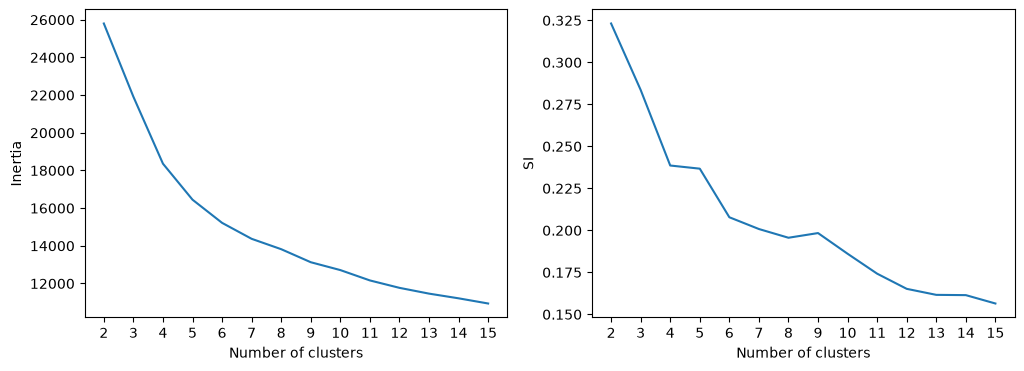

In [12]:
inertia = []
SI = []

for k in range(2, 16):
    kmeans = KMeans(random_state=0, n_clusters=k)
    kmeans.fit(X_pca)

    si = metrics.silhouette_score(X_pca, kmeans.labels_)

    inertia.append(kmeans.inertia_)
    SI.append(si)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(np.arange(2,16),inertia)
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.xticks(np.arange(2,16))
plt.subplot(1,2,2)
plt.plot(np.arange(2,16),SI)
plt.xlabel('Number of clusters')
plt.ylabel('SI')
plt.xticks(np.arange(2,16))
plt.show()

In [13]:
kmeans_first = KMeans(random_state=0, n_clusters=4)
df_p90['Main_Cluster'] = kmeans_first.fit_predict(X_pca)

for i in range(4):
    print(f"\nCluster {i} sample")
    print(df_p90[df_p90['Main_Cluster'] == i][['Player', 'Pos', 'Main_Cluster']].head(5))
    print(len(df_p90))


Cluster 0 sample
               Player    Pos  Main_Cluster
8            Ali Abdi  DF,MF             0
29      Karim Adeyemi  FW,MF             0
30      Simon Adingra  FW,MF             0
37   Oladapo Afolayan  FW,MF             0
66  Maghnes Akliouche  FW,MF             0
1450

Cluster 1 sample
              Player Pos  Main_Cluster
5   Yunis Abdelhamid  DF             1
16       Abdel Abqar  DF             1
20  Francesco Acerbi  DF             1
27  Tosin Adarabioyo  DF             1
38  Emmanuel Agbadou  DF             1
1450

Cluster 2 sample
           Player    Pos  Main_Cluster
6   Himad Abdelli  MF,FW             2
10           Abel     DF             2
14          Abner     DF             2
25    Tyler Adams     MF             2
32    Yacine Adli     MF             2
1450

Cluster 3 sample
               Player    Pos  Main_Cluster
13     Matthis Abline     FW             3
15  Zakaria Aboukhlal  MF,FW             3
18      Tammy Abraham     FW             3
23         Akor

In [14]:
subset = df_p90[df_p90['Main_Cluster'] == 0].copy()

subset_X = StandardScaler().fit_transform(subset[numerical_features + ['Cmp%']])

pca_subset = PCA(n_components=0.90, random_state=0)
subset_X_pca = pca_subset.fit_transform(subset_X)

subset_kmeans = KMeans(random_state=0, n_clusters=3)
subset['Sub_Cluster'] = subset_kmeans.fit_predict(subset_X_pca)

for i in range(3):
    print(f"\n Sub Cluster {i} sample")
    print(subset[subset['Sub_Cluster'] == i][['Player', 'Pos', 'Sub_Cluster']].head(5))
    print(len(subset['Sub_Cluster']))


 Sub Cluster 0 sample
                     Player    Pos  Sub_Cluster
91            Thiago Almada  MF,FW            0
102            Hugo Álvarez  MF,DF            0
114            Nadiem Amiri     MF            0
155  Hákon Arnar Haraldsson  MF,FW            0
167              Iago Aspas  FW,MF            0
241

 Sub Cluster 1 sample
                Player    Pos  Sub_Cluster
29       Karim Adeyemi  FW,MF            1
66   Maghnes Akliouche  FW,MF            1
137             Antony     FW            1
238    Bradley Barcola     FW            1
247      Harvey Barnes     FW            1
241

 Sub Cluster 2 sample
               Player    Pos  Sub_Cluster
8            Ali Abdi  DF,MF            2
30      Simon Adingra  FW,MF            2
37   Oladapo Afolayan  FW,MF            2
85    Mohamed Ali Cho  FW,MF            2
103    Julián Álvarez     FW            2
241


In [15]:
subset.groupby('Sub_Cluster')[['xAG', 'SCA', 'PrgC', 'Tkl', 'Def 3rd_stats_possession']].mean()

,xAG,SCA,PrgC,Tkl,Def 3rd_stats_possession
Sub_Cluster,,,,,
0,0.225113,4.126599,2.808175,1.589758,9.781635
1,0.305155,4.906736,4.715452,1.186327,4.205854
2,0.182844,3.535668,3.538082,1.350918,5.825133



Main-Cluster 0


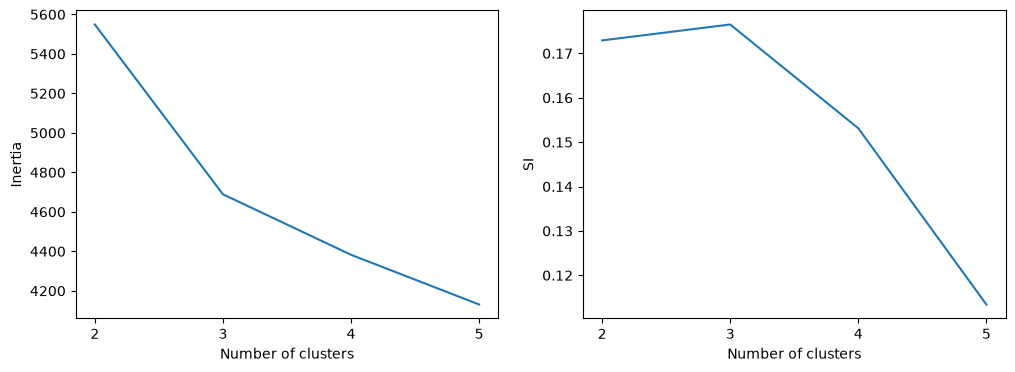


Main-Cluster 1


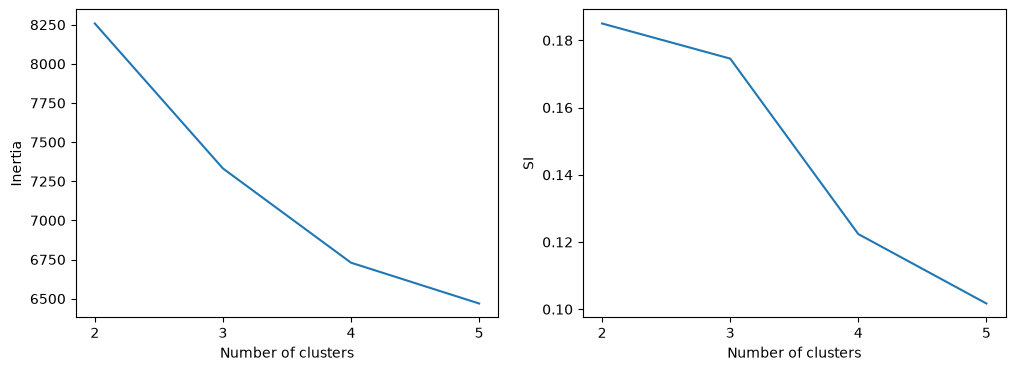


Main-Cluster 2


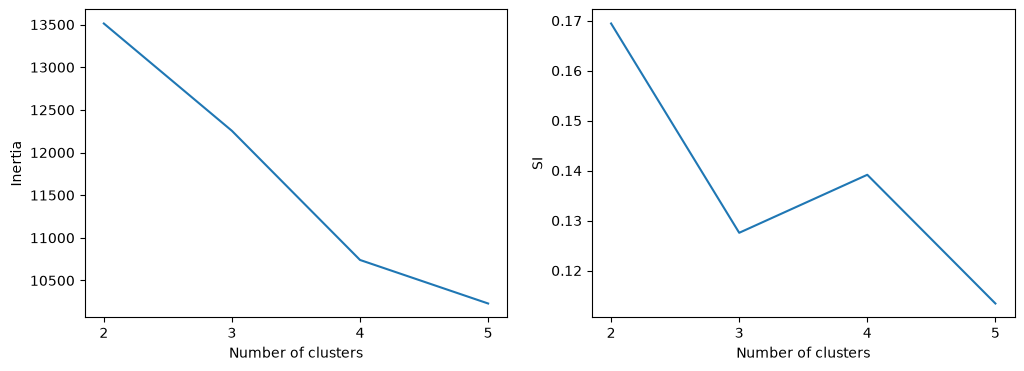


Main-Cluster 3


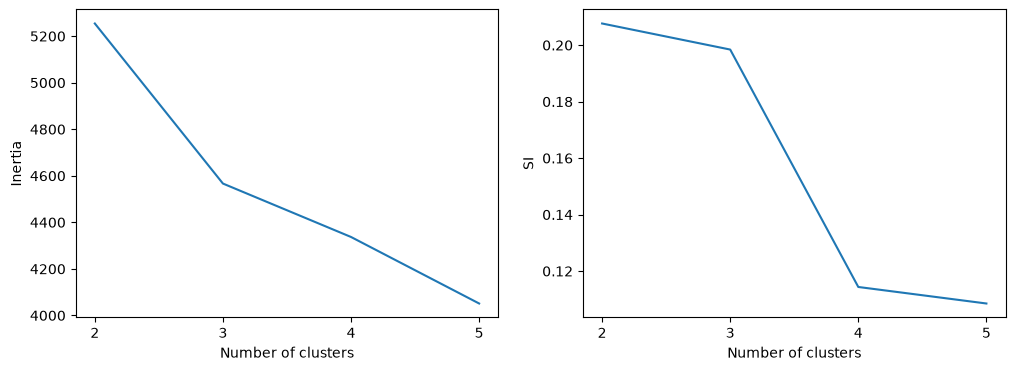

In [16]:
for subset_id in range(4):
    subset = df_p90[df_p90['Main_Cluster'] == subset_id].copy()
    
    subset_X = StandardScaler().fit_transform(subset[numerical_features + ['Cmp%']])
    
    pca_subset = PCA(n_components=0.90, random_state=0)
    subset_X_pca = pca_subset.fit_transform(subset_X)
    
    inertia = []
    SI = []

    for k in range(2, 6):
        kmeans = KMeans(random_state=0, n_clusters=k)
        kmeans.fit(subset_X_pca)

        si = metrics.silhouette_score(subset_X_pca, kmeans.labels_)

        inertia.append(kmeans.inertia_)
        SI.append(si)

    print(f"\nMain-Cluster {subset_id}")
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(np.arange(2,6),inertia)
    plt.xlabel('Number of clusters')
    plt.ylabel('Inertia')
    plt.xticks(np.arange(2,6))
    plt.subplot(1,2,2)
    plt.plot(np.arange(2,6),SI)
    plt.xlabel('Number of clusters')
    plt.ylabel('SI')
    plt.xticks(np.arange(2,6))
    plt.show()

In [17]:
subset_k = [3, 2, 4, 3]
tactical_roles = {}

for subset_id in range(4):
    subset = df_p90[df_p90['Main_Cluster'] == subset_id].copy()

    subset_X = StandardScaler().fit_transform(subset[numerical_features + ['Cmp%']])
    subset_X_pca = PCA(n_components=0.90, random_state=0).fit_transform(subset_X)

    subset_kmeans = KMeans(random_state=0, n_clusters=subset_k[subset_id])
    subset['Sub_Cluster'] = subset_kmeans.fit_predict(subset_X_pca)

    tactical_roles[f"Main_{subset_id}"] = subset

    print(f"Main-Cluster {subset_id}: {subset['Sub_Cluster'].nunique()} micro-roles, {len(subset)} players")

Main-Cluster 0: 3 micro-roles, 241 players
Main-Cluster 1: 2 micro-roles, 363 players
Main-Cluster 2: 4 micro-roles, 596 players
Main-Cluster 3: 3 micro-roles, 250 players


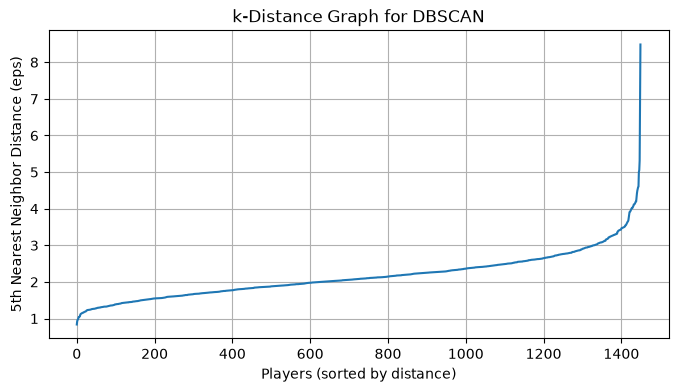

In [18]:
from sklearn.neighbors import NearestNeighbors


neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_pca)
distances, indices = neighbors_fit.kneighbors(X_pca)

distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(8, 4))
plt.plot(distances)
plt.xlabel('Players (sorted by distance)')
plt.ylabel('5th Nearest Neighbor Distance (eps)')
plt.title('k-Distance Graph for DBSCAN')
plt.grid(True)
plt.show()

In [19]:
from sklearn.cluster import DBSCAN
from sklearn import metrics

chosen_eps = 2.2
dbscan = DBSCAN(eps=chosen_eps, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_pca)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"Clusters found: {n_clusters}")
print(f"Noise points (outliers): {n_noise}")

if n_clusters > 1:
    core_mask = dbscan_labels != -1
    si_dbscan = metrics.silhouette_score(X_pca[core_mask], dbscan_labels[core_mask])
    print(f"DBSCAN Silhouette Score: {si_dbscan:.3f}")
else:
    print("DBSCAN found 1 or 0 valid clusters. Cannot calculate Silhouette Score.")

Clusters found: 2
Noise points (outliers): 373
DBSCAN Silhouette Score: 0.252


In [20]:
df_final = pd.concat(tactical_roles.values(), ignore_index=True)

df_final['Tactical_Role'] = 'M' + df_final['Main_Cluster'].astype(str) + '_S' + df_final['Sub_Cluster'].astype(str)

print(f"Total players categorized: {len(df_final)}")
print(f"Unique Tactical Roles: {df_final['Tactical_Role'].nunique()}")

Total players categorized: 1450
Unique Tactical Roles: 12


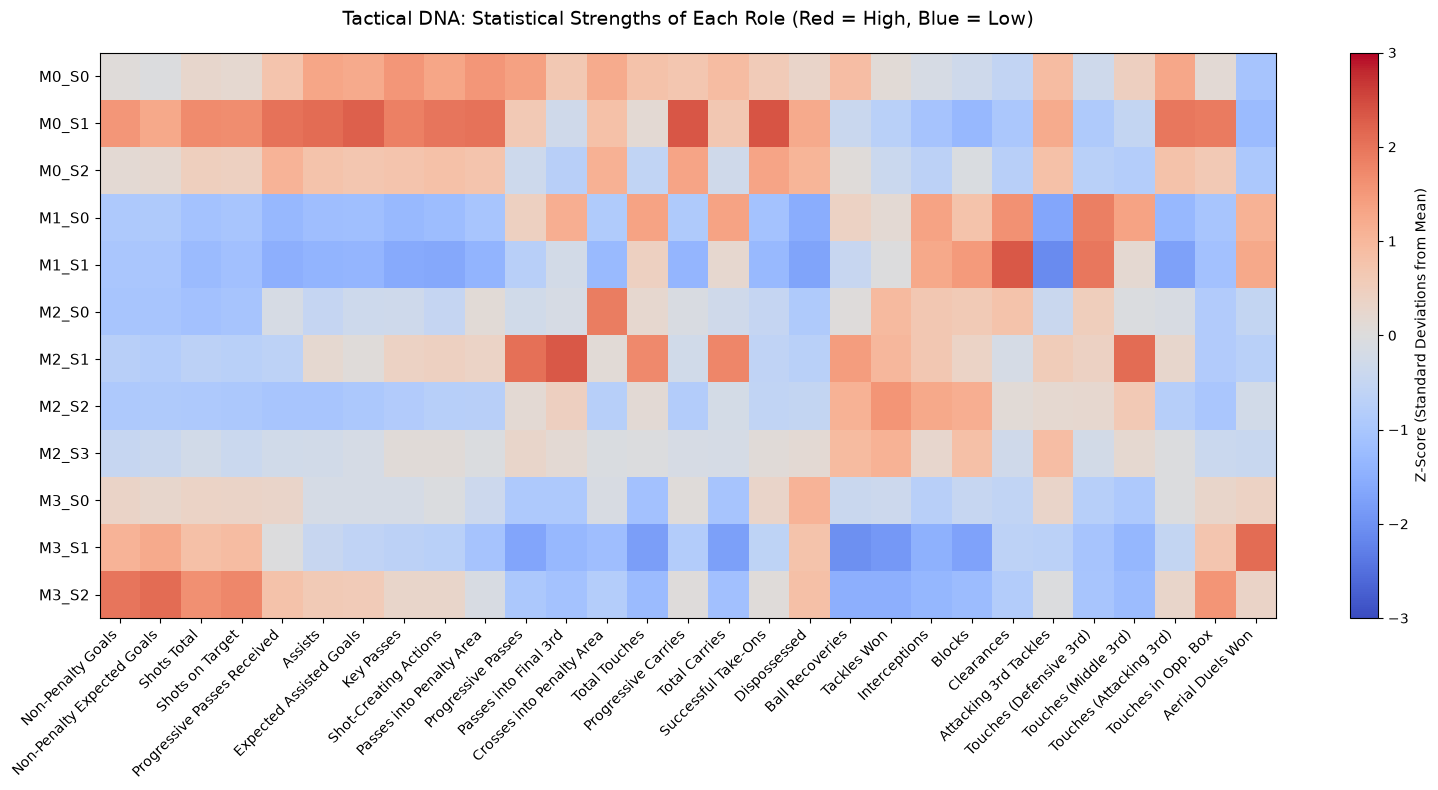

In [21]:
stat_names_mapping = {
    'G-PK': 'Non-Penalty Goals',
    'npxG': 'Non-Penalty Expected Goals',
    'Sh': 'Shots Total',
    'SoT': 'Shots on Target',
    'PrgR': 'Progressive Passes Received',
    'Ast': 'Assists',
    'xAG': 'Expected Assisted Goals',
    'KP': 'Key Passes',
    'SCA': 'Shot-Creating Actions',
    'PPA': 'Passes into Penalty Area',
    'PrgP': 'Progressive Passes',
    'Cmp%': 'Pass Completion %',
    '1/3': 'Passes into Final 3rd',
    'CrsPA': 'Crosses into Penalty Area',
    'Touches': 'Total Touches',
    'PrgC': 'Progressive Carries',
    'Carries': 'Total Carries',
    'Succ': 'Successful Take-Ons',
    'Dis': 'Dispossessed',
    'Recov': 'Ball Recoveries',
    'Tkl': 'Tackles Won',
    'Int': 'Interceptions',
    'Blocks_stats_defense': 'Blocks',
    'Clr': 'Clearances',
    'Att 3rd': 'Attacking 3rd Tackles', 
    'Def 3rd_stats_possession': 'Touches (Defensive 3rd)',
    'Mid 3rd_stats_possession': 'Touches (Middle 3rd)',
    'Att 3rd_stats_possession': 'Touches (Attacking 3rd)',
    'Att Pen': 'Touches in Opp. Box',
    'Won': 'Aerial Duels Won'
}

role_means = df_final.groupby('Tactical_Role')[numerical_features].mean()
scaler = StandardScaler()
role_means_scaled = pd.DataFrame(scaler.fit_transform(role_means), 
                                 columns=role_means.columns, 
                                 index=role_means.index)

role_means_scaled = role_means_scaled.rename(columns=stat_names_mapping)

subset_scaled = role_means_scaled

fig, ax = plt.subplots(figsize=(16, 8))
cax = ax.imshow(subset_scaled, cmap='coolwarm', aspect='auto', vmin=-3, vmax=3)
fig.colorbar(cax, label='Z-Score (Standard Deviations from Mean)')

ax.set_xticks(np.arange(len(subset_scaled.columns)))
ax.set_yticks(np.arange(len(subset_scaled.index)))
ax.set_xticklabels(subset_scaled.columns, rotation=45, ha="right", fontsize=10)
ax.set_yticklabels(subset_scaled.index, fontsize=11)

ax.set_title('Tactical DNA: Statistical Strengths of Each Role (Red = High, Blue = Low)', pad=20, fontsize=14)
plt.tight_layout()
plt.show()

In [22]:
print(df_final['Tactical_Role'].value_counts().sort_index())       # cluster sizes
print(pd.crosstab(df_final['Tactical_Role'], df_final['Pos']))     # roles vs positions
for role, g in df_final.groupby('Tactical_Role'):
    print(role, g.nlargest(5, 'Min')['Player'].tolist())          # example players

Tactical_Role
M0_S0     62
M0_S1     46
M0_S2    133
M1_S0    132
M1_S1    231
M2_S0    164
M2_S1    100
M2_S2    191
M2_S3    141
M3_S0     95
M3_S1    102
M3_S2     53
Name: count, dtype: int64
Pos             DF  DF,FW  DF,MF  FW  FW,DF  FW,MF   MF  MF,DF  MF,FW
Tactical_Role                                                        
M0_S0            7      4      6   1      1      9   18      3     13
M0_S1            0      0      0  16      0     18    1      0     11
M0_S2            0      1      4  26      1     54    7      4     36
M1_S0          120      0      6   0      0      0    4      2      0
M1_S1          216      0      8   0      0      0    5      2      0
M2_S0          129     11     15   0      2      0    1      6      0
M2_S1           21      1      3   0      0      0   63     10      2
M2_S2           26      4      7   0      0      0  137     15      2
M2_S3           13      4      9   2      0      4   74      6     29
M3_S0            0      1      1  